In [129]:
import os 
from pathlib import Path
from dotenv import load_dotenv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
load_dotenv(override=True);

- Compare the average United performance this Premier League season to the game vs Como
 - Compare their last 7 games of 25/26 vs first 7 games of 26/27

In [130]:
data_repo_path = os.getenv('DATA_REPO_PATH')
DATA_REPO_DIR = Path(data_repo_path)

data_repo_base = os.getenv('DATA_REPO_BASE')
DATA_REPO_BASE_DIR = Path(data_repo_base)

In [131]:
ucl_united_csv = DATA_REPO_BASE_DIR / '2026-2027' / 'By Tournament' / 'Champions League' / 'GW8' / 'fixtures.csv'
ucl_united = pd.read_csv(ucl_united_csv)
ucl_united = ucl_united[ucl_united["match_id"] == '26-27-champions-league-como-vs-manchester-united-2026-09-08']

In [132]:
gws_2627 = []

for i in range(1,8):
    gw_united = DATA_REPO_BASE_DIR / '2026-2027' / 'By Tournament' / 'Premier League' / f'GW{i}' / 'fixtures.csv'
    gw_united_stat = pd.read_csv(gw_united)
    gw_united_stat["gameweek"] = i
    
    is_manu = gw_united_stat["match_id"].apply(
        lambda x: "manchester-united" in str(x)
    )
    gws_2627.append(gw_united_stat[is_manu])

gws_stats_2627 = pd.concat(gws_2627, ignore_index=True)

In [133]:
gws_2526 = []

for i in range(32,39):
    gw_united = DATA_REPO_BASE_DIR / '2025-2026' / 'By Tournament' / 'Premier League' / f'GW{i}' / 'fixtures.csv'
    gw_united_stat = pd.read_csv(gw_united)
    gw_united_stat["gameweek"] = i
    
    is_manu = gw_united_stat["match_id"].apply(
        lambda x: "manchester-united" in str(x)
    )
    gws_2526.append(gw_united_stat[is_manu])

gws_stats_2526 = pd.concat(gws_2526, ignore_index=True)

In [134]:
metrics = ['total_shots', 'big_chances', 'touches_in_opposition_box', 'duels_won', 'possession']

home_met = [f"home_{m}" for m in metrics]
away_met = [f"away_{m}" for m in metrics]

home_stats_2627 = gws_stats_2627.groupby("home_team")[home_met].sum()
away_stats_2627 = gws_stats_2627.groupby("away_team")[away_met].sum()

home_stats_2627.columns = metrics
away_stats_2627.columns = metrics

avg_stats_2627 = home_stats_2627.add(away_stats_2627, fill_value=0)

avg_stats_2627 = avg_stats_2627 / 7
avg_stats_2627.round(1)
#####
home_stats_2526 = gws_stats_2526.groupby("home_team")[home_met].sum()
away_stats_2526 = gws_stats_2526.groupby("away_team")[away_met].sum()

home_stats_2526.columns = metrics
away_stats_2526.columns = metrics

avg_stats_2526 = home_stats_2526.add(away_stats_2526, fill_value=0)

avg_stats_2526 = avg_stats_2526 / 7
avg_stats_2526.round(1)

ucl_united = ucl_united[away_met]
ucl_united.columns = metrics


In [135]:
avg_stats_2627 = avg_stats_2627.head(1)
avg_stats_2526 = avg_stats_2526.head(1)

man_u_stats = pd.concat([avg_stats_2526, avg_stats_2627, ucl_united], ignore_index=True)
man_u_stats = man_u_stats.round(0)

In [136]:
man_u_stats["cat"] = ['25/26 GW 32-38', '26/27 GW 1-7', 'vs Como']

In [137]:
man_u_stats

,total_shots,big_chances,touches_in_opposition_box,duels_won,possession,cat
0,15.0,3.0,28.0,48.0,46.0,25/26 GW 32-38
1,20.0,3.0,31.0,47.0,56.0,26/27 GW 1-7
2,13.0,1.0,16.0,48.0,45.0,vs Como


Text(0.5, 0.95, 'Manchester United Performances')

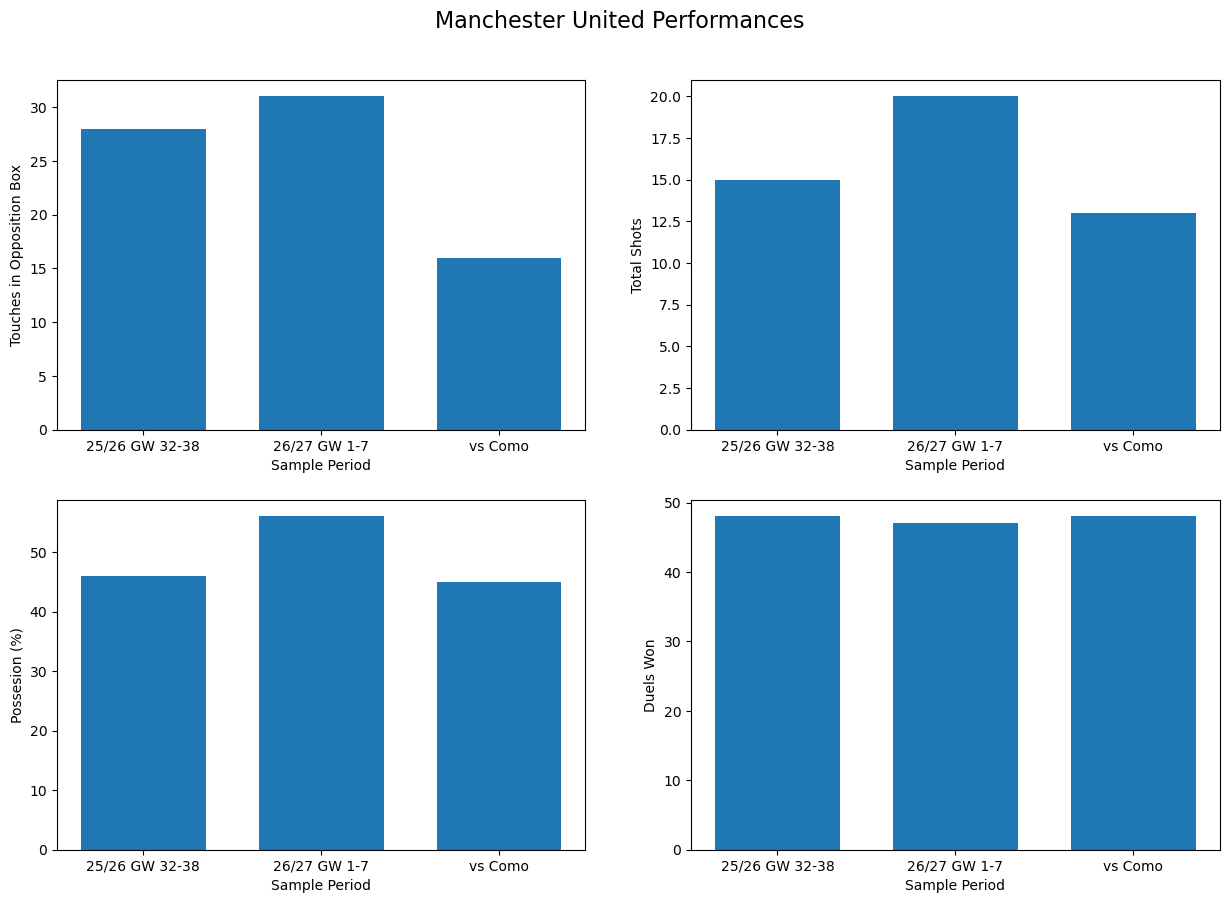

In [138]:
fig, axs = plt.subplots(2, 2, figsize=(15,10))

barlist1 = axs[0,0].bar(man_u_stats["cat"], man_u_stats["touches_in_opposition_box"], width=.7)
axs[0,0].set_xlabel("Sample Period")
axs[0,0].set_ylabel("Touches in Opposition Box")

barlist2 = axs[0,1].bar(man_u_stats["cat"], man_u_stats["total_shots"], width=.7)
axs[0,1].set_xlabel("Sample Period")
axs[0,1].set_ylabel("Total Shots")

barlist3 = axs[1,0].bar(man_u_stats["cat"], man_u_stats["possession"], width=.7)
axs[1,0].set_xlabel("Sample Period")
axs[1,0].set_ylabel("Possesion (%)")

barlist4 = axs[1,1].bar(man_u_stats["cat"], man_u_stats["duels_won"], width=.7)
axs[1,1].set_xlabel("Sample Period")
axs[1,1].set_ylabel("Duels Won")

fig.suptitle("Manchester United Performances", fontsize=16, y=0.95)